In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
import os
from cycler import cycler

semilla = 42
random.seed(semilla)
np.random.seed(semilla)

AZULES = ["#08306b", "#2171b5", "#6baed6", "#c6dbef"]
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=AZULES),
    "image.cmap": "Blues",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Cargar Datos

In [5]:
jp = pd.read_csv("db/2_unido/jugador_partido.csv", low_memory=False)
partidos = pd.read_csv("db/2_unido/partidos.csv")

def resumen_eda(df, primeras):
    resumen = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "pct_nulos": df.isna().mean().mul(100),
        "valores_unicos": df.nunique(),
    })

    resumen["pct_unicos"] = (
        resumen["valores_unicos"] / len(df) * 100
    )

    resumen = resumen.sort_values("pct_nulos", ascending=False)

    # Las variables de 'primeras' arriba, en ese orden; el resto, ordenado por nulos
    primeras = [c for c in primeras if c in resumen.index]
    return pd.concat([resumen.loc[primeras], resumen.drop(index=primeras)])

# EDA JP

In [6]:
resumen_eda(df = jp, primeras = ("player_id",))

,tipo,nulos,pct_nulos,valores_unicos,pct_unicos
player_id,int64,0,0.000000,1796,1.940950
fm_expected_goals_on_target_faced,float64,87921,95.016859,434,0.469027
fm_goals_conceded,float64,86393,93.365538,9,0.009726
fm_expected_goals_on_target_variant,float64,21566,23.306532,257,0.277742
fm_rating_title,float64,6564,7.093762,634,0.685168
...,...,...,...,...,...
goals,int64,0,0.000000,5,0.005404
emparejamiento,object,0,0.000000,4,0.004323
tm_player_id,int64,0,0.000000,1796,1.940950
emparejamiento_tm,object,0,0.000000,4,0.004323


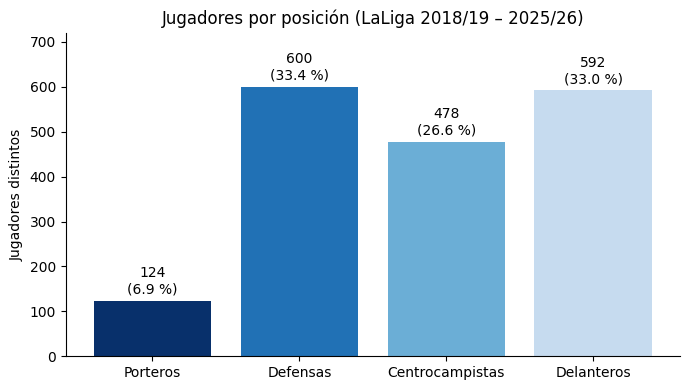

In [16]:
base = jp[jp.fm_player_id.notna()]           # quita las 34 filas sin FotMob
centros = base[base.tm_posicion == "Midfield"]
delanteros = base[base.tm_posicion == "Attack"]
defensas = base[base.tm_posicion == "Defender"]
porteros = base[base.tm_posicion == "Goalkeeper"]

# Gráfico posiciones
grupos = {"Porteros": porteros, "Defensas": defensas,
          "Centrocampistas": centros, "Delanteros": delanteros}

n_jugadores = pd.Series({pos: df["player_id"].nunique() for pos, df in grupos.items()})
pct = n_jugadores / n_jugadores.sum() * 100

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(n_jugadores.index, n_jugadores, color=AZULES)
ax.bar_label(barras, labels=[f"{n}\n({p:.1f} %)" for n, p in zip(n_jugadores, pct)], padding=3)
ax.set_ylabel("Jugadores distintos")
ax.set_title("Jugadores por posición (LaLiga 2018/19 – 2025/26)")
ax.set_ylim(0, n_jugadores.max() * 1.2)
plt.tight_layout()
plt.show()

## Boxplot minutos jugados

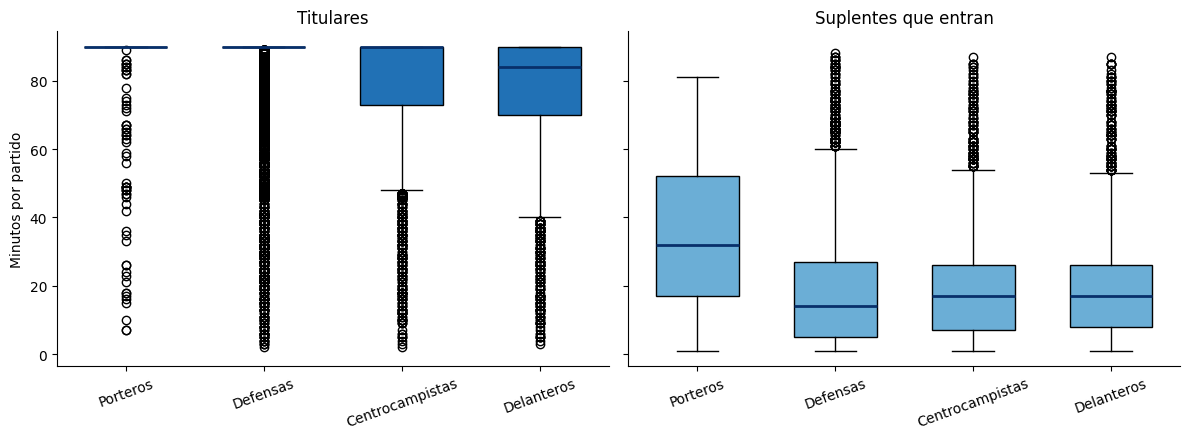

In [17]:
etiquetas = list(grupos.keys())
titulares = [df.loc[df.position != "Sub", "minutes"] for df in grupos.values()]
suplentes = [df.loc[df.position == "Sub", "minutes"] for df in grupos.values()]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, datos, titulo, color in zip(axes, [titulares, suplentes],
                                    ["Titulares", "Suplentes que entran"], [AZULES[1], AZULES[2]]):
    bp = ax.boxplot(datos, tick_labels=etiquetas, patch_artist=True, widths=0.6,
                    medianprops={"color": AZULES[0], "linewidth": 2})
    for caja in bp["boxes"]:
        caja.set_facecolor(color)
    ax.set_title(titulo)
    ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("Minutos por partido")
plt.tight_layout()
plt.show()

- Los suplentes juegan menos (obvio)
- Los defensas y los porteros juegan los 90 minutos prácticamente siempre
- Los centros y los delanteros son los que menos juegan pero los centros tienen siempre una mediana más alta.
- Los porteros suplentes juegan más pero porque suelen entrar por lesión del otro portero
- Los defensas suplentes juegan menos porque normalmente cambias a los otros cuando están cansados y si eso.
- Los centros y los delanteros suelen entrar sobre los últimos minutos del partido, por lo que no es raro que jueguen como mucho 20 mins

## Correlaciones Jugadores

Jugador-temporada con ≥ 900': 2514 {'Defensas': 1014, 'Centrocampistas': 762, 'Delanteros': 738}


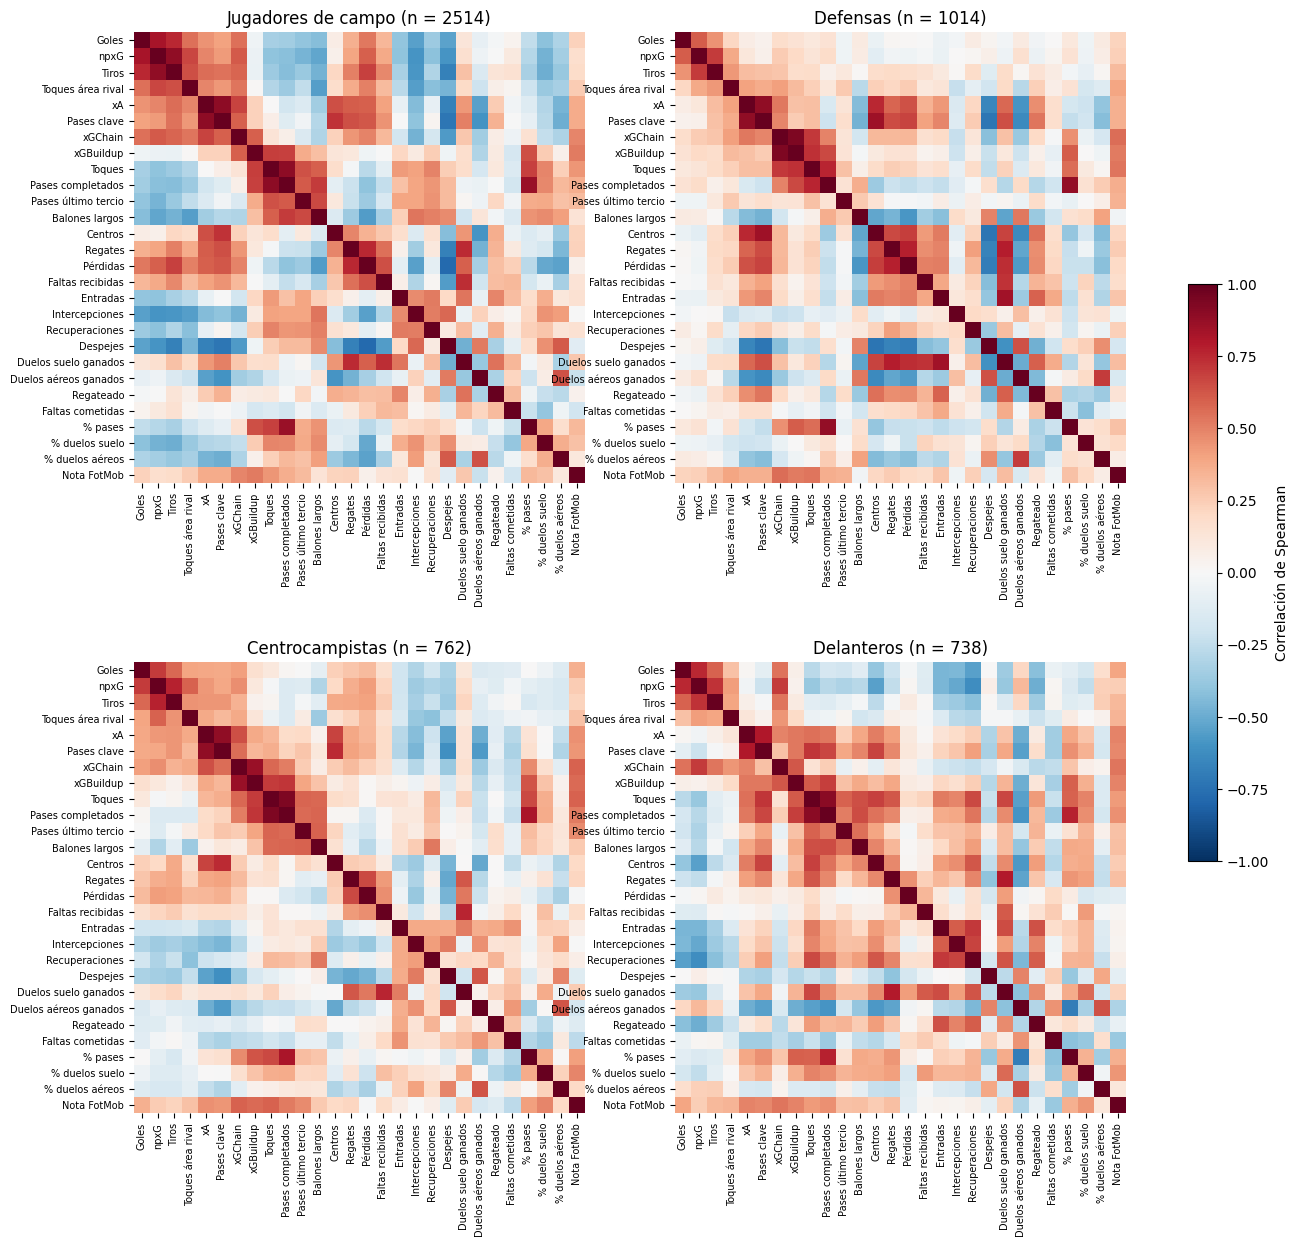


Jugadores de campo: pares con |r| ≥ 0,8
Toques             Pases completados    0.90
xA                 Pases clave          0.90
npxG               Tiros                0.88
Pases completados  % pases              0.87
Goles              npxG                 0.82

Defensas: pares con |r| ≥ 0,8
xGChain            xGBuildup               0.94
xA                 Pases clave             0.89
Pases completados  % pases                 0.88
Pases clave        Centros                 0.85
Entradas           Duelos suelo ganados    0.84

Centrocampistas: pares con |r| ≥ 0,8
Toques             Pases completados    0.94
xA                 Pases clave          0.89
xGChain            xGBuildup            0.86
Pases completados  % pases              0.82

Delanteros: pares con |r| ≥ 0,8
Toques  Pases completados    0.91
xA      Pases clave          0.80


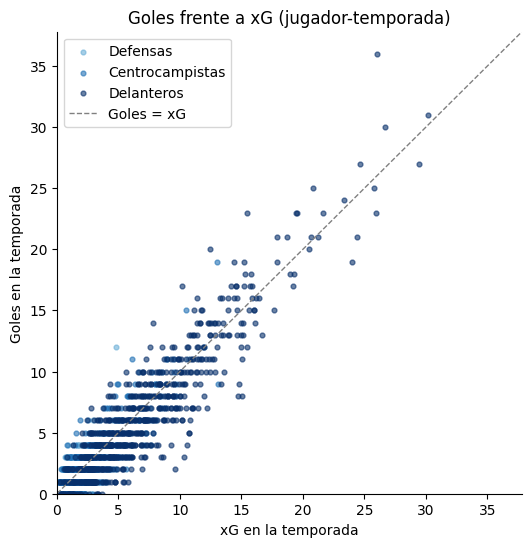

Correlación goles-xG: 0.934


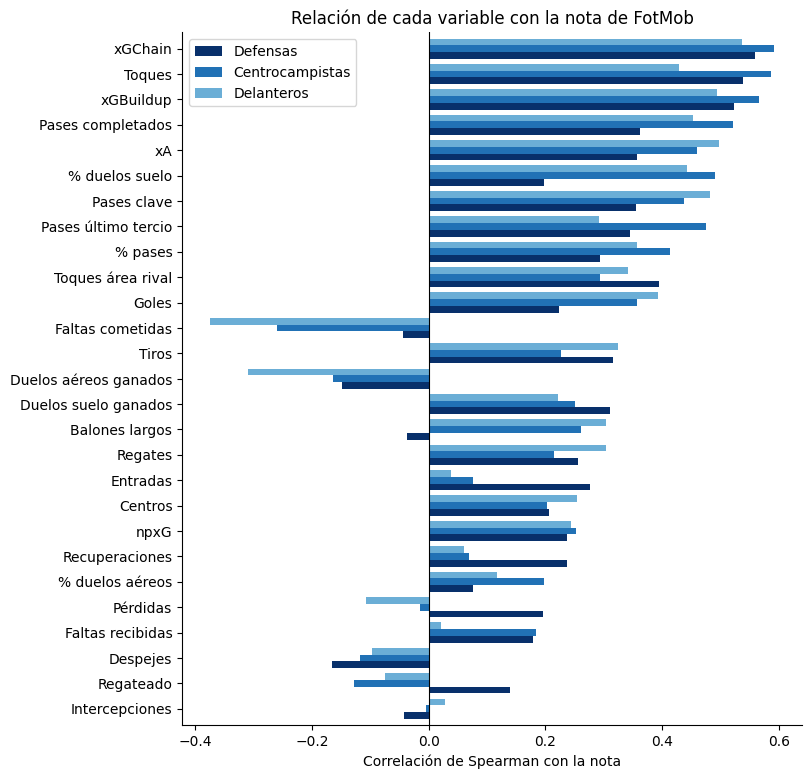

In [18]:
MIN_MINUTOS = 900          # umbral de minutos por temporada

# Variables de conteo -> se pasan a "por 90 minutos" (columna: etiqueta)
CONTEOS = {
    # Ataque
    "goals": "Goles", "np_xg": "npxG", "shots": "Tiros", "fm_touches_opp_box": "Toques área rival",
    # Creación
    "xa": "xA", "key_passes": "Pases clave", "xg_chain": "xGChain", "xg_buildup": "xGBuildup",
    # Posesión
    "fm_touches": "Toques", "fm_accurate_passes": "Pases completados",
    "fm_passes_into_final_third": "Pases último tercio", "fm_long_balls_accurate": "Balones largos",
    "fm_accurate_crosses": "Centros", "fm_dribbles_succeeded": "Regates",
    "fm_dispossessed": "Pérdidas", "fm_was_fouled": "Faltas recibidas",
    # Defensa
    "fm_matchstats.headers.tackles": "Entradas", "fm_interceptions": "Intercepciones",
    "fm_recoveries": "Recuperaciones", "fm_clearances": "Despejes",
    "fm_ground_duels_won": "Duelos suelo ganados", "fm_aerials_won": "Duelos aéreos ganados",
    "fm_dribbled_past": "Regateado", "fm_fouls": "Faltas cometidas",
}
POSICIONES = {"Defender": "Defensas", "Midfield": "Centrocampistas", "Attack": "Delanteros"}

# --- Tabla jugador-temporada (solo jugadores de campo) ---
campo = base[base.tm_posicion.isin(POSICIONES)].copy()
campo["nota_x_min"] = campo.fm_rating_title * campo.minutes          # nota media ponderada por minutos
campo["min_con_nota"] = campo.minutes.where(campo.fm_rating_title.notna(), 0)

jt = campo.groupby(["season", "player_id"]).agg(
    jugador=("player", "first"), posicion=("tm_posicion", "first"), minutos=("minutes", "sum"),
    **{c: (c, "sum") for c in CONTEOS},
    xg_total=("xg", "sum"),
    pases_total=("fm_accurate_passes_total", "sum"),
    duelos_total=("fm_ground_duels_won_total", "sum"), aereos_total=("fm_aerials_won_total", "sum"),
    nota_x_min=("nota_x_min", "sum"), min_con_nota=("min_con_nota", "sum"),
).reset_index()
jt = jt[jt.minutos >= MIN_MINUTOS]

for c, etiqueta in CONTEOS.items():
    jt[etiqueta] = jt[c] / jt.minutos * 90
jt["% pases"] = jt.fm_accurate_passes / jt.pases_total * 100
jt["% duelos suelo"] = jt.fm_ground_duels_won / jt.duelos_total * 100
jt["% duelos aéreos"] = jt.fm_aerials_won / jt.aereos_total * 100
jt["Nota FotMob"] = jt.nota_x_min / jt.min_con_nota
jt["posicion"] = jt.posicion.map(POSICIONES)

VARS = list(CONTEOS.values()) + ["% pases", "% duelos suelo", "% duelos aéreos", "Nota FotMob"]
print(f"Jugador-temporada con ≥ {MIN_MINUTOS}': {len(jt)}", jt.posicion.value_counts().to_dict())


def mapa_correlaciones(df, titulo, ax):
    """Correlación de Spearman, azul (negativa) - blanco (0) - rojo (positiva)."""
    corr = df[VARS].corr(method="spearman")
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(VARS)), VARS, rotation=90, fontsize=7)
    ax.set_yticks(range(len(VARS)), VARS, fontsize=7)
    ax.set_title(f"{titulo} (n = {len(df)})")
    ax.spines[:].set_visible(False)
    return im, corr


# --- 5a. Mapas de correlación: todos y por posición ---
fig, axes = plt.subplots(2, 2, figsize=(16, 15))
grupos_jt = [("Jugadores de campo", jt)] + [(p, jt[jt.posicion == p]) for p in POSICIONES.values()]
correlaciones = {}
for ax, (titulo, df) in zip(axes.flat, grupos_jt):
    im, correlaciones[titulo] = mapa_correlaciones(df, titulo, ax)
fig.colorbar(im, ax=axes, shrink=0.5, label="Correlación de Spearman")
plt.show()


# --- 5b. Pares muy correlacionados (posibles redundancias) ---
def pares_correlados(corr, umbral=0.8):
    sup = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
    return sup[sup.abs() >= umbral].sort_values(key=abs, ascending=False).round(2)

for titulo, corr in correlaciones.items():
    print(f"\n{titulo}: pares con |r| ≥ 0,8")
    print(pares_correlados(corr).to_string())


# --- 5c. xG frente a goles (los dos incluyen penaltis) ---
fig, ax = plt.subplots(figsize=(6, 6))
for pos, color in zip(["Defensas", "Centrocampistas", "Delanteros"], [AZULES[2], AZULES[1], AZULES[0]]):
    df = jt[jt.posicion == pos]
    ax.scatter(df.xg_total, df.goals, s=12, alpha=0.6, color=color, label=pos)
lim = jt[["xg_total", "goals"]].max().max() * 1.05
ax.plot([0, lim], [0, lim], ls="--", color="grey", lw=1, label="Goles = xG")
ax.set(xlabel="xG en la temporada", ylabel="Goles en la temporada", xlim=(0, lim), ylim=(0, lim),
       title="Goles frente a xG (jugador-temporada)")
ax.legend()
plt.show()
print("Correlación goles-xG:", round(jt.goals.corr(jt.xg_total), 3))


# --- 5d. ¿Qué valora la nota de FotMob? ---
nota = pd.DataFrame({p: c["Nota FotMob"].drop("Nota FotMob") for p, c in correlaciones.items()
                     if p != "Jugadores de campo"})
nota = nota.loc[nota.abs().max(axis=1).sort_values().index]
ax = nota.plot.barh(figsize=(8, 9), color=AZULES[:3], width=0.8)
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Correlación de Spearman con la nota", title="Relación de cada variable con la nota de FotMob")
plt.show()

In [10]:
VARS_GK = {
    "fm_saves": "Paradas",
    "fm_goals_conceded": "Goles encajados",
    "fm_expected_goals_on_target_faced": "xGOT recibido",
}
faltan = [c for c in VARS_GK if c not in base.columns]
assert not faltan, f"Estas columnas no existen, revisa el nombre: {faltan}"

porteros = base[base.tm_posicion == "Goalkeeper"].copy()
print(f"{porteros.player_id.nunique()} porteros, {len(porteros)} apariciones")

# % de vacíos por temporada (el xGOT debería estar vacío solo antes de la 20/21)
porteros.groupby("season")[list(VARS_GK) + ["fm_rating_title"]].apply(
    lambda d: d.isna().mean().mul(100).round(1)
)

124 porteros, 6139 apariciones


,fm_saves,fm_goals_conceded,fm_expected_goals_on_target_faced,fm_rating_title
season,,,,
1819,0.0,0.0,100.0,0.1
1920,0.0,0.0,99.5,0.5
2021,0.0,0.0,0.0,0.0
2122,0.0,0.0,0.0,0.3
2223,0.0,0.0,0.0,0.4
2324,0.0,0.0,0.0,0.1
2425,0.0,0.0,0.0,0.1
2526,0.0,0.0,0.0,0.0


## EDA porteros

In [11]:
VARS_GK = {
    "fm_saves": "Paradas",
    "fm_goals_conceded": "Goles encajados",
    "fm_expected_goals_on_target_faced": "xGOT recibido",
}
faltan = [c for c in VARS_GK if c not in base.columns]
assert not faltan, f"Estas columnas no existen, revisa el nombre: {faltan}"

porteros = base[base.tm_posicion == "Goalkeeper"].copy()
print(f"{porteros.player_id.nunique()} porteros, {len(porteros)} apariciones")

# % de vacíos por temporada (el xGOT debería estar vacío solo antes de la 20/21)
porteros.groupby("season")[list(VARS_GK) + ["fm_rating_title"]].apply(
    lambda d: d.isna().mean().mul(100).round(1)
)

124 porteros, 6139 apariciones


,fm_saves,fm_goals_conceded,fm_expected_goals_on_target_faced,fm_rating_title
season,,,,
1819,0.0,0.0,100.0,0.1
1920,0.0,0.0,99.5,0.5
2021,0.0,0.0,0.0,0.0
2122,0.0,0.0,0.0,0.3
2223,0.0,0.0,0.0,0.4
2324,0.0,0.0,0.0,0.1
2425,0.0,0.0,0.0,0.1
2526,0.0,0.0,0.0,0.0


In [13]:
MIN_MINUTOS = 900

# El xGOT solo se usa desde la 20/21 (en la 19/20 hay 2 partidos sueltos que se descartan)
porteros["xgot"] = porteros.fm_expected_goals_on_target_faced.where(porteros.season >= 2021)
porteros["nota_x_min"] = porteros.fm_rating_title * porteros.minutes
porteros["min_con_nota"] = porteros.minutes.where(porteros.fm_rating_title.notna(), 0)

gt = porteros.groupby(["season", "player_id"]).agg(
    jugador=("player", "first"),
    equipo=("team", "last"),
    partidos=("minutes", "size"),
    minutos=("minutes", "sum"),
    paradas=("fm_saves", "sum"),
    goles_encajados=("fm_goals_conceded", "sum"),
    xgot=("xgot", lambda s: s.sum(min_count=1)),   # vacío si no hay xGOT esa temporada
    nota_x_min=("nota_x_min", "sum"),
    min_con_nota=("min_con_nota", "sum"),
).reset_index()

gt = gt[gt.minutos >= MIN_MINUTOS].copy()
p90 = gt.minutos / 90
gt["encajados_90"] = gt.goles_encajados / p90
gt["paradas_90"] = gt.paradas / p90
gt["pct_paradas"] = 100 * gt.paradas / (gt.paradas + gt.goles_encajados)
gt["xgot_90"] = gt.xgot / p90
gt["evitados_90"] = (gt.xgot - gt.goles_encajados) / p90
gt["nota"] = gt.nota_x_min / gt.min_con_nota
gt = gt.drop(columns=["nota_x_min", "min_con_nota"])

print(f"{len(gt)} porteros-temporada con {MIN_MINUTOS}' o más "
      f"({gt.xgot.notna().sum()} con xGOT, desde la 20/21)")

205 porteros-temporada con 900' o más (154 con xGOT, desde la 20/21)


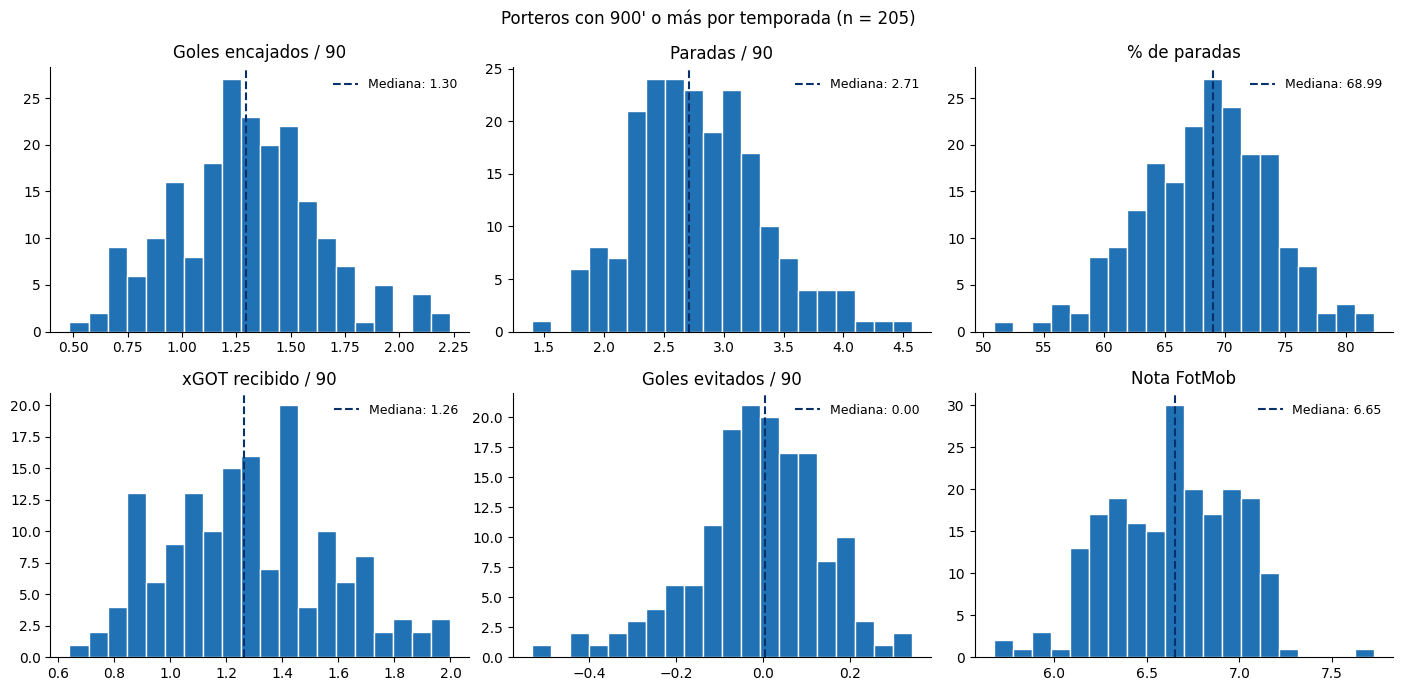

,count,mean,std,min,25%,50%,75%,max
encajados_90,205.0,1.29,0.33,0.48,1.09,1.30,1.50,2.23
paradas_90,205.0,2.79,0.54,1.40,2.43,2.71,3.12,4.57
pct_paradas,205.0,68.44,5.41,50.85,64.84,68.99,71.92,82.35
xgot_90,154.0,1.28,0.29,0.64,1.07,1.26,1.45,2.00
evitados_90,154.0,-0.01,0.15,-0.53,-0.09,0.00,0.08,0.34
nota,205.0,6.63,0.34,5.67,6.36,6.65,6.91,7.73


In [14]:
VARS_PLOT = {
    "encajados_90": "Goles encajados / 90",
    "paradas_90": "Paradas / 90",
    "pct_paradas": "% de paradas",
    "xgot_90": "xGOT recibido / 90",
    "evitados_90": "Goles evitados / 90",
    "nota": "Nota FotMob",
}

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, etiqueta) in zip(axes.flat, VARS_PLOT.items()):
    datos = gt[col].dropna()
    ax.hist(datos, bins=20, color=AZULES[1], edgecolor="white")
    ax.axvline(datos.median(), color=AZULES[0], ls="--", lw=1.5,
               label=f"Mediana: {datos.median():.2f}")
    ax.set_title(etiqueta)
    ax.legend(frameon=False, fontsize=9)
fig.suptitle(f"Porteros con {MIN_MINUTOS}' o más por temporada (n = {len(gt)})")
fig.tight_layout()
plt.show()

gt[list(VARS_PLOT)].describe().T.round(2)

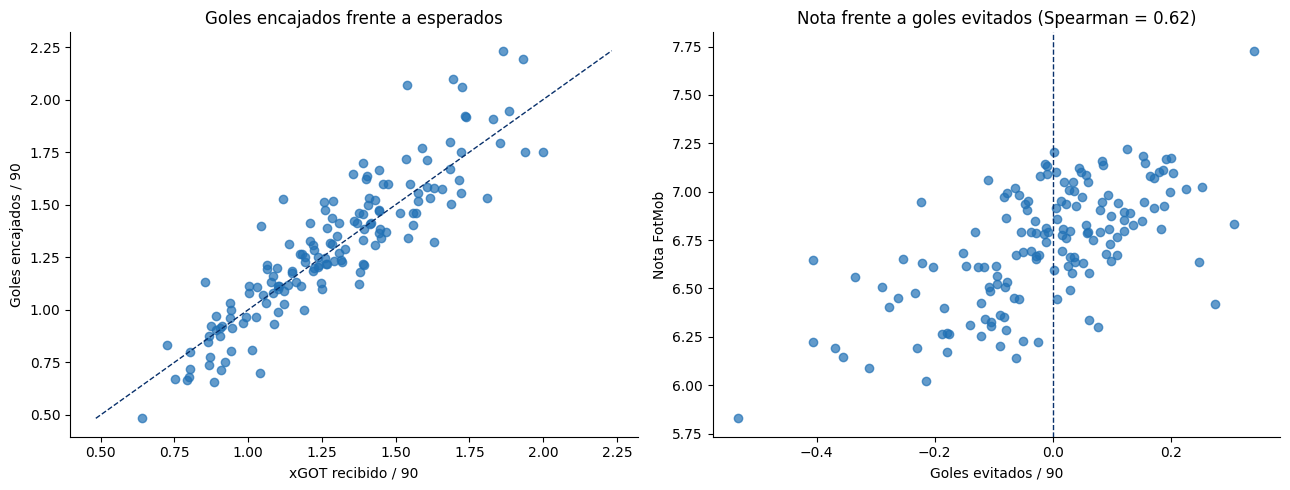

,encajados_90,paradas_90,pct_paradas,xgot_90,evitados_90,nota
encajados_90,1.00,0.46,-0.71,0.91,-0.42,-0.51
paradas_90,0.46,1.00,0.22,0.65,0.31,0.17
pct_paradas,-0.71,0.22,1.00,-0.47,0.73,0.71
xgot_90,0.91,0.65,-0.47,1.00,-0.06,-0.31
evitados_90,-0.42,0.31,0.73,-0.06,1.00,0.62
nota,-0.51,0.17,0.71,-0.31,0.62,1.00


,season,jugador,equipo,minutos,evitados_90,pct_paradas,nota
333,2526,Joan García,Barcelona,2700,0.34,77.89,7.73
173,2223,Paulo Gazzaniga,Girona,2520,0.31,71.54,6.83
125,2021,Edgar Badía,Elche,2700,0.28,67.38,6.42
251,2324,Giorgi Mamardashvili,Valencia,3288,0.25,72.48,7.02
202,2223,Edgar Badía,Elche,3240,0.25,68.81,6.64
98,2021,Jan Oblak,Atletico Madrid,3420,0.23,80.47,7.02
241,2324,Andriy Lunin,Real Madrid,1890,0.20,73.85,7.10
293,2425,Joan García,Espanyol,3420,0.20,74.11,7.18
203,2223,Ivo Grbic,Atletico Madrid,916,0.20,75.00,7.00
181,2223,Gerónimo Rulli,Villarreal,1260,0.19,82.14,7.17


,season,jugador,equipo,minutos,evitados_90,pct_paradas,nota
132,2122,Sergio Rico,Mallorca,1260,-0.53,50.85,5.83
184,2223,Sergio Asenjo,Real Valladolid,900,-0.41,59.62,6.22
212,2223,Agustín Marchesín,Celta Vigo,1710,-0.41,60.27,6.65
145,2122,Aitor Fernández,Levante,1169,-0.37,64.20,6.19
187,2223,Benjamin Lecomte,Espanyol,900,-0.35,67.44,6.15
190,2223,Fernando Pacheco,Espanyol,1530,-0.34,62.77,6.56
242,2324,Iñaki Peña,Barcelona,900,-0.31,56.41,6.09
259,2324,Augusto Batalla,Granada,1530,-0.29,67.82,6.51
137,2122,Jan Oblak,Atletico Madrid,3420,-0.28,60.55,6.40
289,2425,Karl Hein,Real Valladolid,2790,-0.26,58.54,6.45


In [15]:
x = gt.dropna(subset=["xgot_90"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# xGOT recibido frente a goles encajados: por debajo de la diagonal, para más de lo esperado
ax1.scatter(x.xgot_90, x.encajados_90, color=AZULES[1], alpha=0.7)
lim = [x[["xgot_90", "encajados_90"]].min().min(), x[["xgot_90", "encajados_90"]].max().max()]
ax1.plot(lim, lim, color=AZULES[0], ls="--", lw=1)
ax1.set_xlabel("xGOT recibido / 90")
ax1.set_ylabel("Goles encajados / 90")
ax1.set_title("Goles encajados frente a esperados")

# Qué valora la nota de FotMob en los porteros
rho = x[["evitados_90", "nota"]].corr(method="spearman").iloc[0, 1]
ax2.scatter(x.evitados_90, x.nota, color=AZULES[1], alpha=0.7)
ax2.axvline(0, color=AZULES[0], ls="--", lw=1)
ax2.set_xlabel("Goles evitados / 90")
ax2.set_ylabel("Nota FotMob")
ax2.set_title(f"Nota frente a goles evitados (Spearman = {rho:.2f})")

fig.tight_layout()
plt.show()

# Correlaciones entre las variables de portero
display(x[list(VARS_PLOT)].corr(method="spearman").round(2))

# Comprobación de sentido común: mejores y peores por goles evitados
cols = ["season", "jugador", "equipo", "minutos", "evitados_90", "pct_paradas", "nota"]
display(x.nlargest(10, "evitados_90")[cols].round(2))
display(x.nsmallest(10, "evitados_90")[cols].round(2))

# EDA Partidos

## Distribución datos partidos

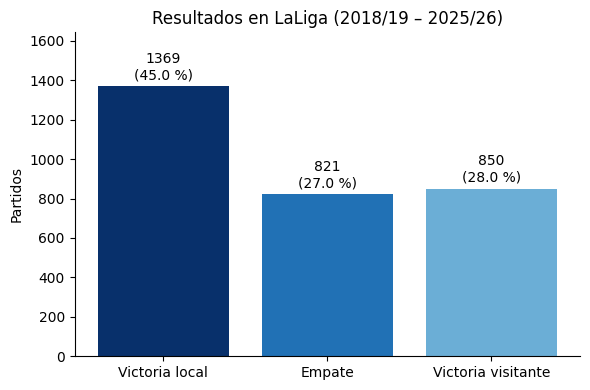

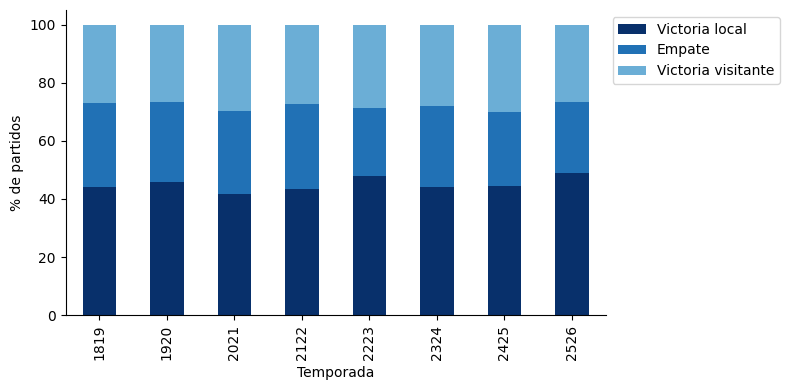

In [12]:
# Resultado desde el punto de vista del local
partidos["resultado"] = np.select(
    [partidos.home_goals > partidos.away_goals,
     partidos.home_goals == partidos.away_goals],
    ["Victoria local", "Empate"],
    default="Victoria visitante",
)
orden = ["Victoria local", "Empate", "Victoria visitante"]
colores = AZULES[:3]          # oscuro = local, medio = empate, claro = visitante

# Distribución total
frec = partidos["resultado"].value_counts().reindex(orden)
pct = frec / frec.sum() * 100
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(orden, frec, color=colores)
ax.bar_label(barras, labels=[f"{n}\n({p:.1f} %)" for n, p in zip(frec, pct)], padding=3)
ax.set_ylabel("Partidos")
ax.set_title("Resultados en LaLiga (2018/19 – 2025/26)")
ax.set_ylim(0, frec.max() * 1.2)
plt.tight_layout()
plt.show()

# Por temporada
tabla = pd.crosstab(partidos["season"], partidos["resultado"], normalize="index")[orden] * 100
ax = tabla.plot(kind="bar", stacked=True, figsize=(8, 4), color=colores)
ax.set_ylabel("% de partidos")
ax.set_xlabel("Temporada")
ax.legend(title="", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()